# DM_EG distributions: real FRB data vs. simulations

One panel per telescope (3 rows x 3 columns), all sharing the same x and y axes and bins.
Simulation files are 2D arrays: column 0 = DM, column 1 = weight.

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import ks_1samp

# ---- config ----
DATA_DIR = Path('DM_distribution_real_data')   # real-data CSVs
SIM_DIR = Path('DM_distribution')              # simulation .npy files
DM_COL = 'DM_EG'                               # column name in the CSVs
NBINS = 30
DENSITY = True                                 # False -> raw counts

# panel title -> real-data csv (order = left-to-right, top-to-bottom)
FILES = {
    "ASKAP fly's eye": 'askap_flyeye.csv',
    'ASKAP ICS': 'askap_ics.csv',
    'Parkes': 'parkes.csv',
    'FAST CRAFTS': 'fast.csv',
    'FAST GPPS': 'fast_plane.csv',
    'Apertif': 'apertif.csv',
    'DSA-110': 'dsa-110.csv',
    'MeerKAT CB': 'meerkat_CB.csv',
    'MeerKAT IB': 'meerkat_IB.csv',
    
}

# panel title -> simulation npy
SIM_FILES = {
    "ASKAP fly's eye": 'DM_distribution_askap_fe.npy',
    'ASKAP ICS': 'DM_distribution_askap_ics.npy',
    'Parkes': 'DM_distribution_parkes.npy',
    'FAST CRAFTS': 'DM_distribution_fast.npy',
    'FAST GPPS': 'DM_distribution_fast_plane.npy',
    'Apertif': 'DM_distribution_apertif.npy',
    'DSA-110': 'DM_distribution_dsa110.npy',
    'MeerKAT CB': 'DM_distribution_meerkat_cb.npy',
    'MeerKAT IB': 'DM_distribution_meerkat_ib.npy'    
}

In [42]:
%matplotlib inline

## Load real data

In [43]:
def load_dm(fname):
    """Read a CSV and return the DM_EG column as a clean numpy array."""
    df = pd.read_csv(DATA_DIR / fname)
    cols = {c.strip().lower(): c for c in df.columns}
    if DM_COL.lower() in cols:
        col = cols[DM_COL.lower()]
    else:
        col = df.select_dtypes('number').columns[0]
        print(f'[warn] {fname}: no "{DM_COL}" column, using "{col}" instead. Columns: {list(df.columns)}')
    return pd.to_numeric(df[col], errors='coerce').dropna().to_numpy()

data = {name: load_dm(f) for name, f in FILES.items()}

for name, d in data.items():
    print(f'{name:18s} N = {len(d):5d}   median = {np.median(d):7.1f}   max = {d.max():7.1f}')

ASKAP fly's eye    N =    25   median =   366.5   max =   952.3
ASKAP ICS          N =    43   median =   353.9   max =  1631.3
Parkes             N =    30   median =   814.0   max =  3301.1
FAST CRAFTS        N =     5   median =  1669.7   max =  1813.0
FAST GPPS          N =     7   median =  1166.9   max =  2292.8
Apertif            N =    24   median =   578.6   max =  2736.2
DSA-110            N =    43   median =   445.2   max =  1371.7
MeerKAT CB         N =    16   median =   812.6   max =  2620.3
MeerKAT IB         N =    15   median =   706.5   max =  1953.4


## Load simulations (DM, weight)

In [44]:
def load_sim(fname):
    """Return (DM, weight) arrays from a simulation .npy (col 0 = DM, col 1 = weight)."""
    arr = np.load(SIM_DIR / fname)
    dm, w = arr[:, 0].astype(float), arr[:, 1].astype(float)
    ok = np.isfinite(dm) & np.isfinite(w) & (w > 0)
    return dm[ok], w[ok]

def weighted_cdf(dm, w):
    """Sorted DM and the normalised cumulative weight."""
    o = np.argsort(dm)
    dm, c = dm[o], np.cumsum(w[o])
    return dm, c / c[-1]

def weighted_median(dm, w):
    dm_s, c = weighted_cdf(dm, w)
    return dm_s[np.searchsorted(c, 0.5)]

sim = {name: load_sim(f) for name, f in SIM_FILES.items()}

for name in data:
    dm, w = sim[name]
    print(f'{name:18s} real: N={len(data[name]):3d} med={np.median(data[name]):7.1f} | '
          f'sim: sum(w)={w.sum():7.1f}  weighted med={weighted_median(dm, w):7.1f}')

ASKAP fly's eye    real: N= 25 med=  366.5 | sim: sum(w)=  374.1  weighted med=   71.0
ASKAP ICS          real: N= 43 med=  353.9 | sim: sum(w)= 5584.2  weighted med=  163.0
Parkes             real: N= 30 med=  814.0 | sim: sum(w)= 4384.1  weighted med=  400.0
FAST CRAFTS        real: N=  5 med= 1669.7 | sim: sum(w)= 9102.4  weighted med= 1003.0
FAST GPPS          real: N=  7 med= 1166.9 | sim: sum(w)= 7973.6  weighted med=  981.0
Apertif            real: N= 24 med=  578.6 | sim: sum(w)= 6837.2  weighted med=  345.0
DSA-110            real: N= 43 med=  445.2 | sim: sum(w)=32998.3  weighted med=  204.0
MeerKAT CB         real: N= 16 med=  812.6 | sim: sum(w)=100628.1  weighted med=  656.0
MeerKAT IB         real: N= 15 med=  706.5 | sim: sum(w)=107181.8  weighted med=  369.0


## Histograms: real vs. simulation, with medians

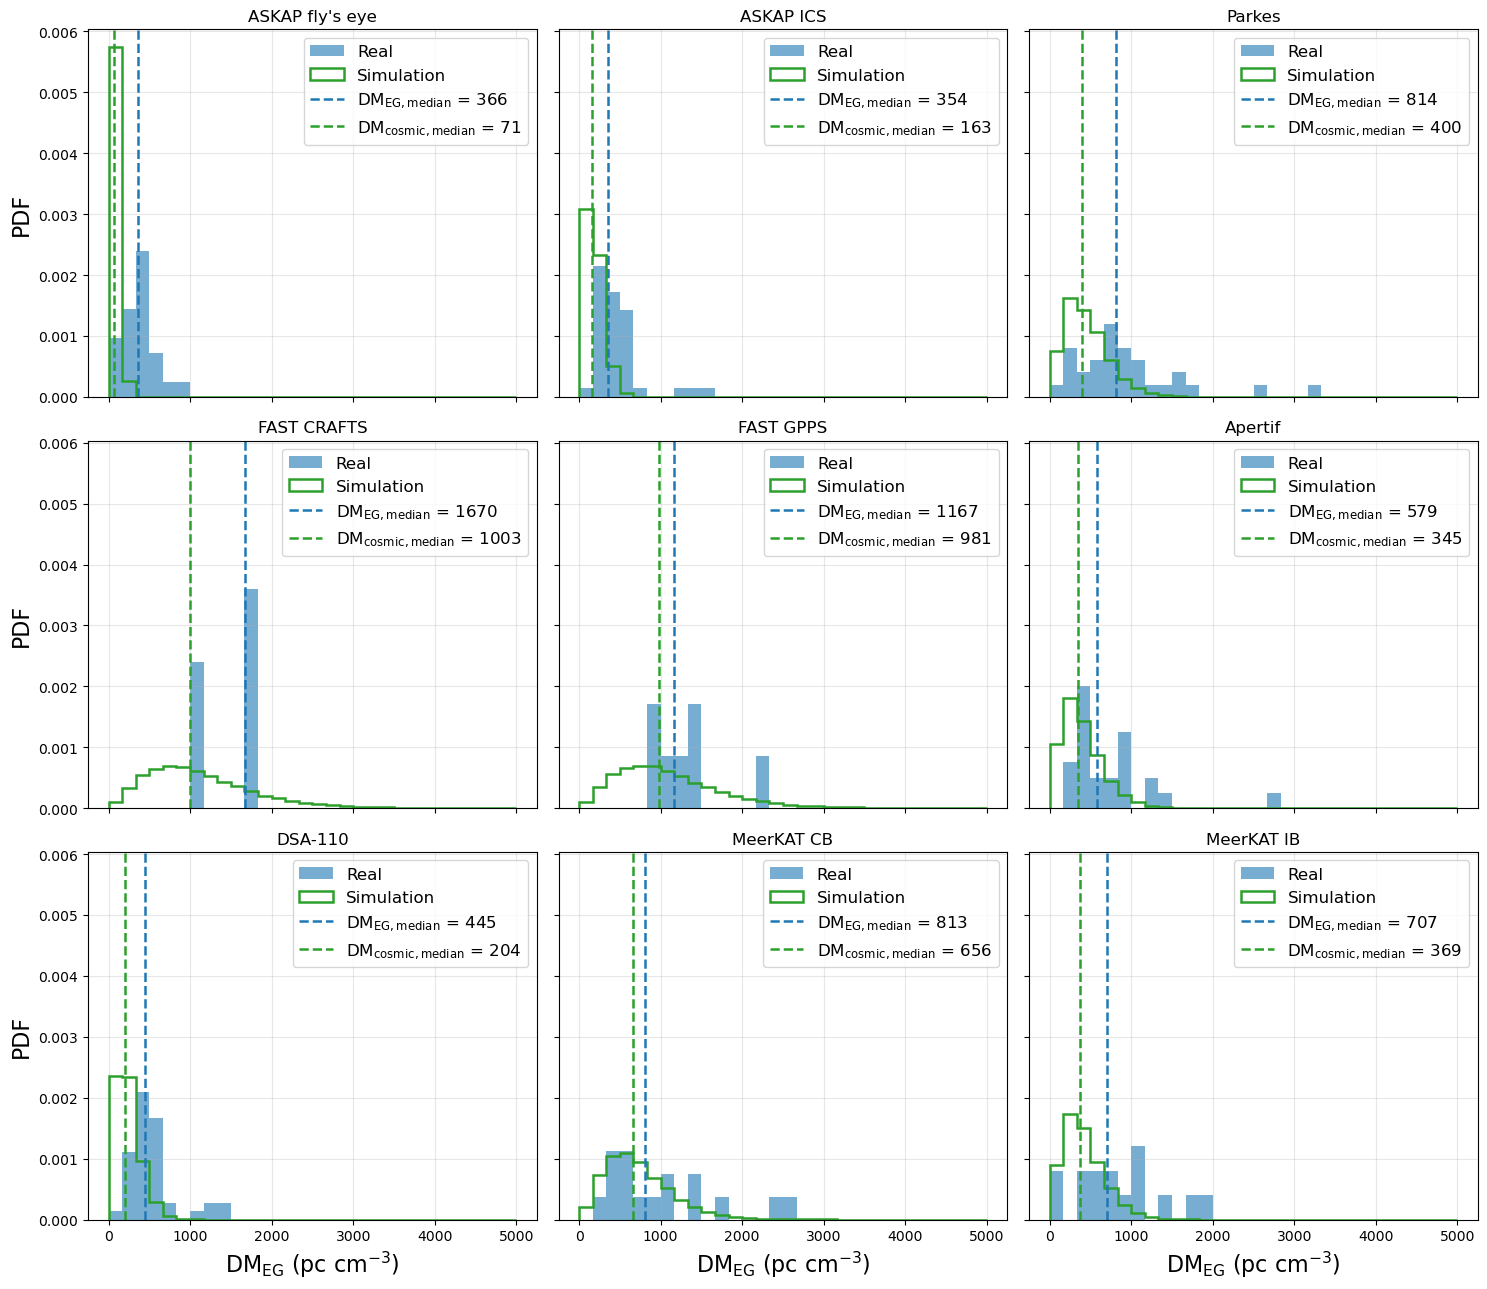

In [45]:
# identical bins for every panel (cover both real and simulated DMs)
all_max = max(max(d.max() for d in data.values()),
              max(dm.max() for dm, _ in sim.values()))
bins = np.linspace(0, all_max, NBINS + 1)

fig, axes = plt.subplots(3, 3, figsize=(15, 13), sharex=True, sharey=True)

for ax, name in zip(axes.flat, data):
    d = data[name]
    s_dm, s_w = sim[name]
    s_med = weighted_median(s_dm, s_w)

    ax.hist(d, bins=bins, density=DENSITY, color='tab:blue', alpha=0.6,
             linewidth=0.5, label='Real')
    ax.hist(s_dm, bins=bins, weights=s_w, density=DENSITY, histtype='step',
            color='tab:green', linewidth=1.8, label='Simulation')

    ax.axvline(np.median(d), color='tab:blue', ls='--', lw=1.8,
               label=f'DM$_{{\\rm EG,median}}$ = {np.median(d):.0f}')
    ax.axvline(s_med, color='tab:green', ls='--', lw=1.8,
               label=f'DM$_{{\\rm cosmic,median}}$ = {s_med:.0f}')

    # ax.set_title(f'{name} (N_real={len(d)}, N_sim={s_w.sum():.0f})', fontsize=10)
    ax.set_title(f'{name}', fontsize=12)
# 
    
    ax.grid(alpha=0.3)
    ax.legend(fontsize=12)

# axis labels only on the outer panels
for ax in axes[-1, :]:
    ax.set_xlabel(r'DM$_{\rm EG}$ (pc cm$^{-3}$)', fontsize=16)
for ax in axes[:, 0]:
    ax.set_ylabel('PDF' if DENSITY else 'Counts', fontsize=16)

plt.tight_layout()
# plt.savefig('DM_EG_distribution_real_vs_sim.png', dpi=300, bbox_inches='tight')
plt.show()

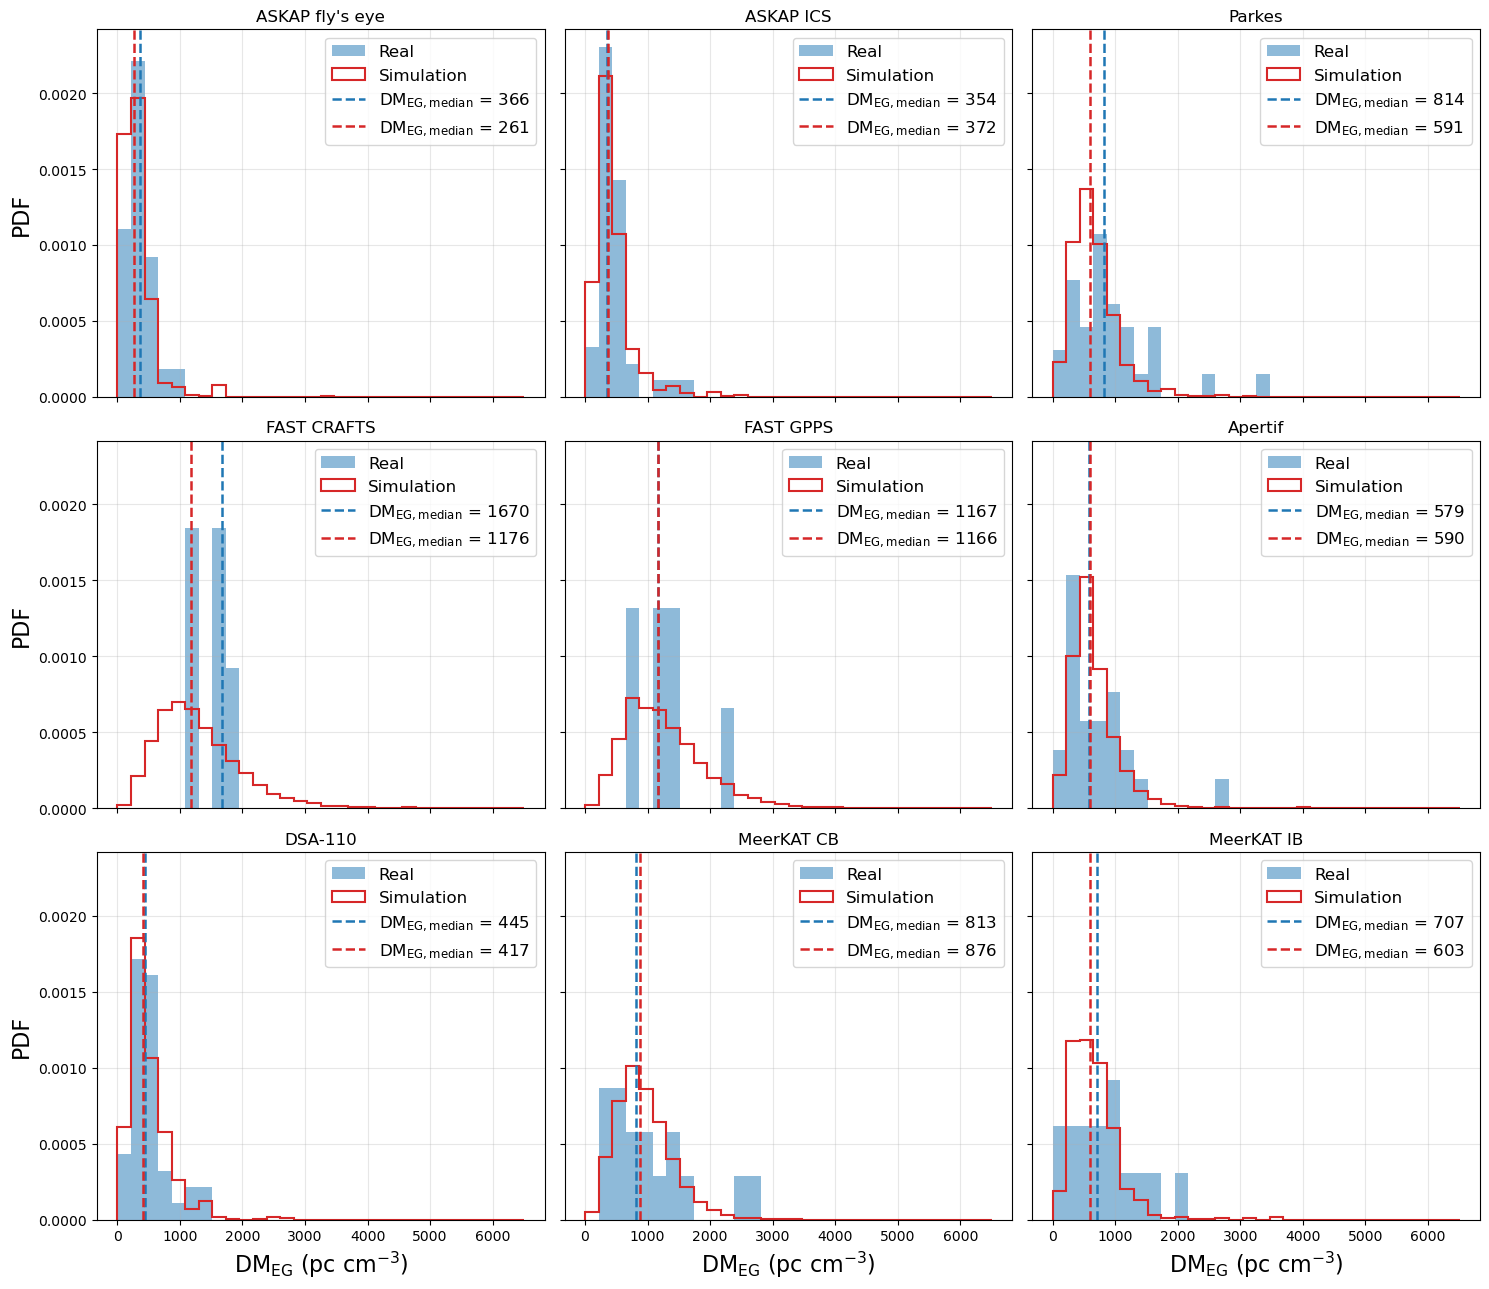

In [46]:
# ---- host DM config ----
HOST_MEDIAN = 200    # pc cm^-3; median of the lognormal (ln-space mean = ln(100))
HOST_SIGMA = 1      # ln-space width (must be positive)
DM_PER_Z = 1000.0      # simulation uses DM = 1000 * z
rng = np.random.default_rng(42)

def add_host(dm, w):
    """Add a lognormal DM_host/(1+z) to every simulated burst; weights unchanged."""
    z = dm / DM_PER_Z
    host = rng.lognormal(np.log(HOST_MEDIAN), abs(HOST_SIGMA), size=len(dm))
    return dm + host / (1 + z), w

sim_host = {name: add_host(*sim[name]) for name in sim}

# ---- histograms: real vs sim vs sim + host ----
all_max = max(max(d.max() for d in data.values()),
              max(dm.max() for dm, _ in sim_host.values()))
bins = np.linspace(0, all_max, NBINS + 1)

fig, axes = plt.subplots(3, 3, figsize=(15, 13), sharex=True, sharey=True)

for ax, name in zip(axes.flat, data):
    d = data[name]
    s_dm, s_w = sim[name]
    h_dm, h_w = sim_host[name]
    h_med = weighted_median(h_dm, h_w)

    ax.hist(d, bins=bins, density=DENSITY, color='tab:blue', alpha=0.5, linewidth=0.5, label='Real')
    # ax.hist(s_dm, bins=bins, weights=s_w, density=DENSITY, histtype='step',
    #         color='tab:red', ls=':', linewidth=1.2, alpha=0.7, label='Sim (no host)')
    ax.hist(h_dm, bins=bins, weights=h_w, density=DENSITY, histtype='step',
            color='tab:red', linewidth=1.5, label='Simulation')

    ax.axvline(np.median(d), color='tab:blue', ls='--', lw=1.8,
               label=f'DM$_{{\\rm EG,median}}$ = {np.median(d):.0f}')
    ax.axvline(h_med, color='tab:red', ls='--', lw=1.8,
               label=f'DM$_{{\\rm EG,median}}$ = {h_med:.0f}')

    # ax.set_title(f'{name} (N_real={len(d)}, N_sim={s_w.sum():.0f})', fontsize=10)
    ax.set_title(f'{name}', fontsize=12)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=12)

for ax in axes[-1, :]:
    ax.set_xlabel(r'DM$_{\rm EG}$ (pc cm$^{-3}$)', fontsize=16)
for ax in axes[:, 0]:
    ax.set_ylabel('PDF' if DENSITY else 'Counts', fontsize=16)

plt.tight_layout()
# plt.savefig('DM_EG_distribution_real_vs_sim_host.png', dpi=300, bbox_inches='tight')
plt.show()

## Cumulative distributions with K-S test

One-sample K-S test of the real DMs against the weighted simulated CDF (`ks_2samp` does not support weights).

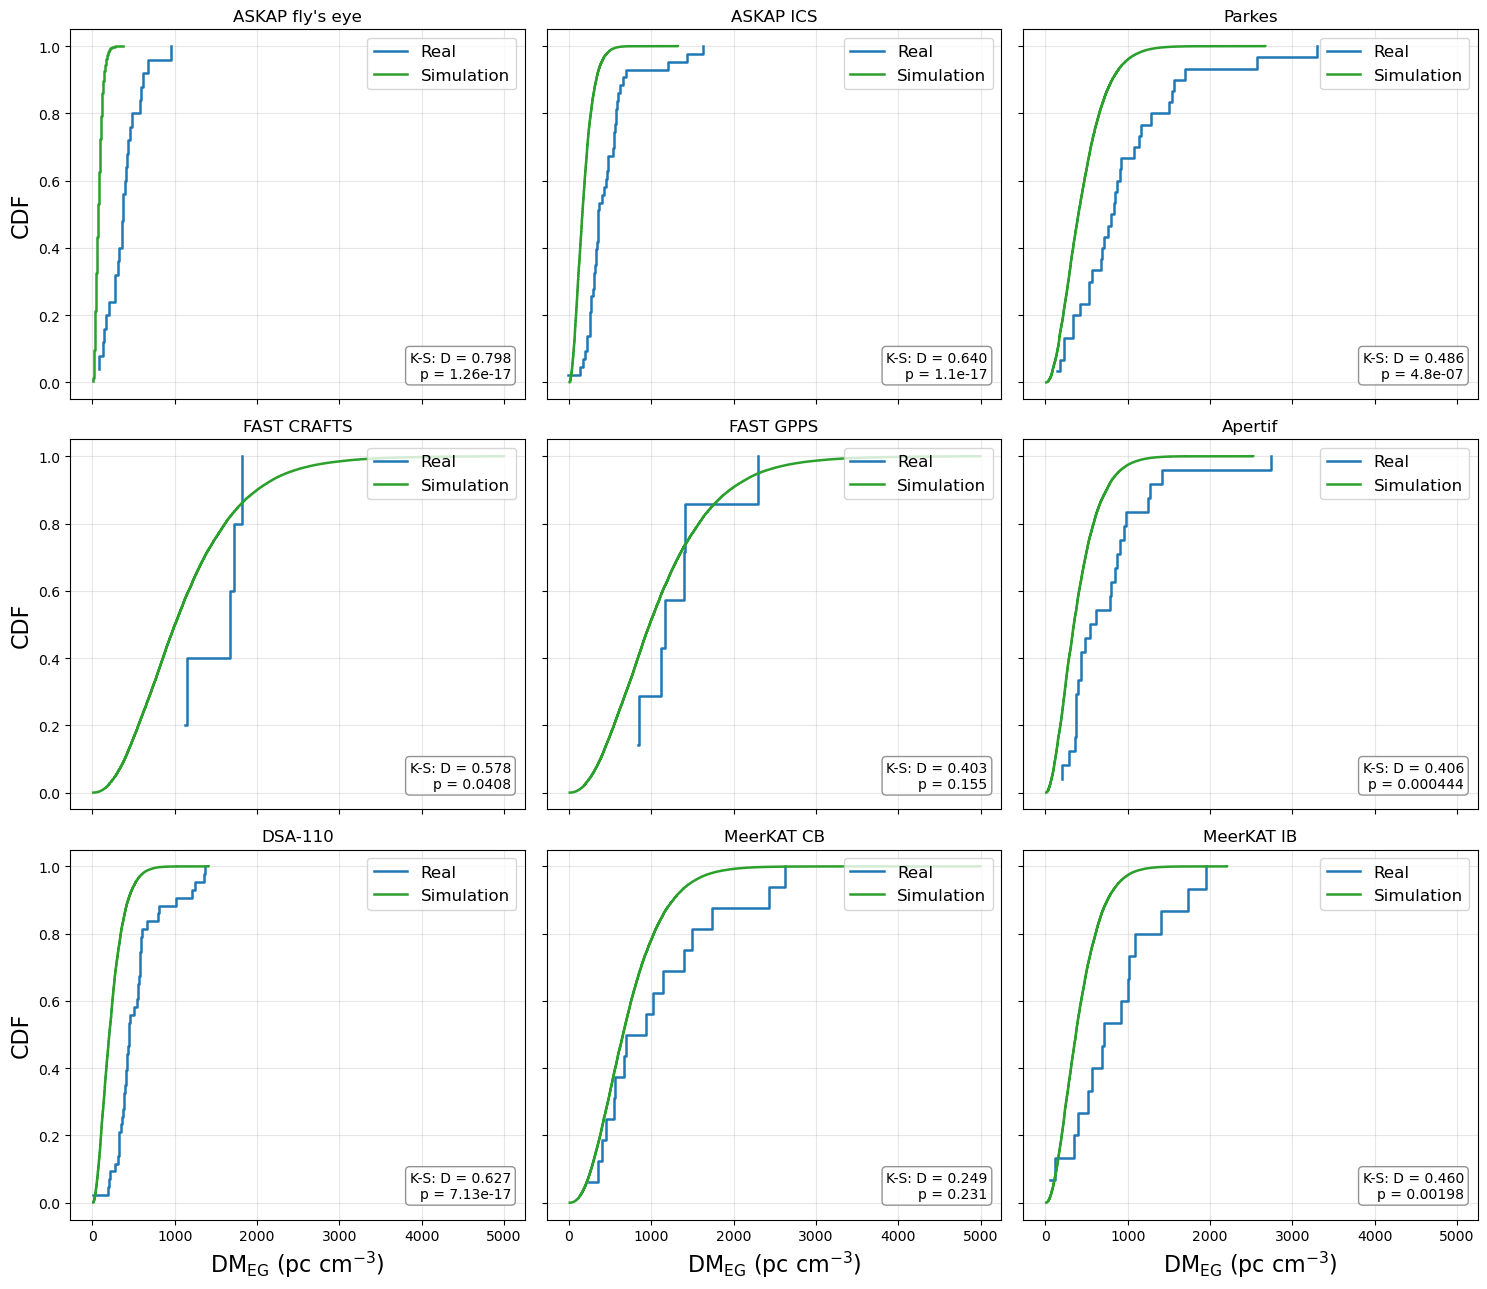

In [47]:
fig, axes = plt.subplots(3, 3, figsize=(15, 13), sharex=True, sharey=True)

for ax, name in zip(axes.flat, data):
    d = np.sort(data[name])
    s_dm, s_w = sim[name]
    s_sorted, s_cdf = weighted_cdf(s_dm, s_w)

    ax.step(d, np.arange(1, len(d) + 1) / len(d), where='post',
            color='tab:blue', lw=1.8, label='Real')
    ax.step(s_sorted, s_cdf, where='post', color='tab:green', lw=1.8,
            label='Simulation')

    # real DMs vs the simulated (weighted) CDF
    model_cdf = lambda x, xs=s_sorted, cs=s_cdf: np.interp(x, xs, cs, left=0, right=1)
    res = ks_1samp(d, model_cdf)

    ax.text(0.97, 0.05, f'K-S: D = {res.statistic:.3f}\np = {res.pvalue:.3g}',
            transform=ax.transAxes, ha='right', va='bottom', fontsize=10,
            bbox=dict(boxstyle='round', fc='white', ec='gray', alpha=0.85))

    ax.set_title(name, fontsize=12)
    ax.grid(alpha=0.3)
    ax.legend(loc='upper right', fontsize=12    )

for ax in axes[-1, :]:
    ax.set_xlabel(r'DM$_{\rm EG}$ (pc cm$^{-3}$)', fontsize=16)
for ax in axes[:, 0]:
    ax.set_ylabel('CDF', fontsize=16)

plt.tight_layout()
# plt.savefig('DM_EG_cdf_real_vs_sim.png', dpi=300, bbox_inches='tight')
plt.show()

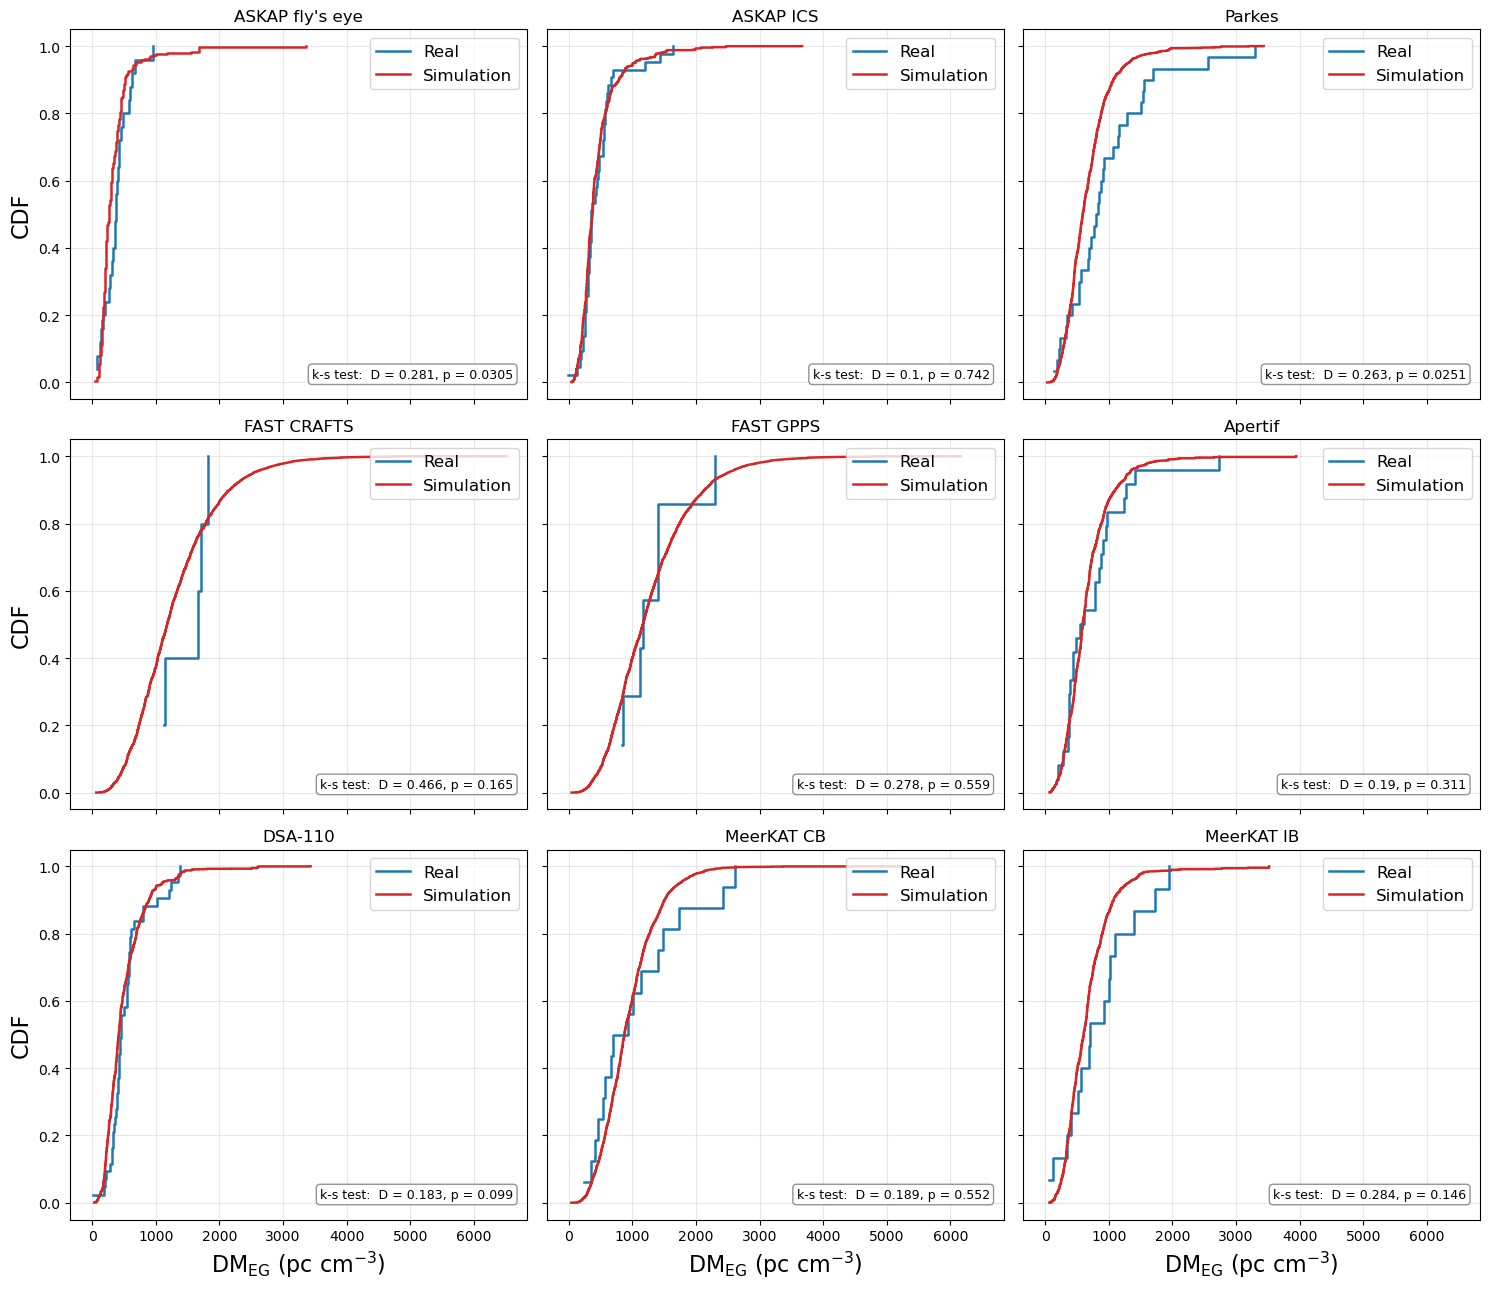

In [48]:
# ---- CDFs: real vs sim vs sim + host, with K-S tests ----
def ks_vs_sim(d, s_dm, s_w):
    xs, cs = weighted_cdf(s_dm, s_w)
    return ks_1samp(d, lambda x: np.interp(x, xs, cs, left=0, right=1))

fig, axes = plt.subplots(3, 3, figsize=(15, 13), sharex=True, sharey=True)

for ax, name in zip(axes.flat, data):
    d = np.sort(data[name])
    s_dm, s_w = sim[name]
    h_dm, h_w = sim_host[name]
    s_x, s_c = weighted_cdf(s_dm, s_w)
    h_x, h_c = weighted_cdf(h_dm, h_w)

    ax.step(d, np.arange(1, len(d) + 1) / len(d), where='post',
            color='tab:blue', lw=1.8, label='Real')
    # ax.step(s_x, s_c, where='post', color='tab:red', ls=':', lw=1.3, alpha=0.7,
    #         label='Sim (no host)')
    ax.step(h_x, h_c, where='post', color='tab:red', lw=1.8, label='Simulation')

    r0, r1 = ks_vs_sim(d, s_dm, s_w), ks_vs_sim(d, h_dm, h_w)
    ax.text(0.97, 0.05,
            f'k-s test:  D = {r1.statistic:.3g}, p = {r1.pvalue:.3g}',
            transform=ax.transAxes, ha='right', va='bottom', fontsize=9,
            bbox=dict(boxstyle='round', fc='white', ec='gray', alpha=0.85))

    ax.set_title(name, fontsize=12)
    ax.grid(alpha=0.3)
    ax.legend(loc='upper right', fontsize=12)

for ax in axes[-1, :]:
    ax.set_xlabel(r'DM$_{\rm EG}$ (pc cm$^{-3}$)', fontsize=16)
for ax in axes[:, 0]:
    ax.set_ylabel('CDF', fontsize=16)

plt.tight_layout()
# plt.savefig('DM_EG_cdf_real_vs_sim_host.png', dpi=300, bbox_inches='tight')
plt.show()